# Quantum 4×4 Sudoku Solver

Solving a 4x4 sudoku board with Grover's search

Circuit:


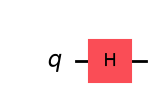


State vector: Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
  |0> amplitude: 0.7071+0.0000j  probability 50.00%
  |1> amplitude: 0.7071+0.0000j  probability 50.00%

Bloch sphere:


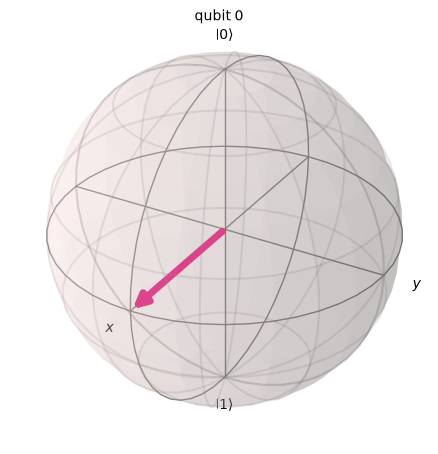

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

# Single qubit starts in |0>, apply H to put it in superposition
qc = QuantumCircuit(1)
qc.h(0)

print('Circuit:')
display(qc.draw('mpl'))

# simulated state
sv = Statevector(qc)
print(f'\nState vector: {sv}')
print(f'  |0> amplitude: {sv[0]:.4f}  probability {abs(sv[0])**2:.2%}')
print(f'  |1> amplitude: {sv[1]:.4f}  probability {abs(sv[1])**2:.2%}')

print('\nBloch sphere:')
display(plot_bloch_multivector(sv))

## search register

two qubits have 4 possible basis states: |00⟩, |01⟩, |10⟩, |11⟩.
n qubits have 2^n basis states, 2^n amplitudes

apply H to every qubit and all basis states get equal amplitude simultaneously

all candidate solutions exist at once

2 qubit circuit with 2 haramards


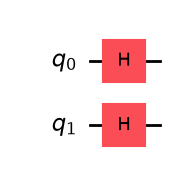

amplitudes over all 4 basis states
  |00> amplitude=0.5000+0.0000j  probability=25.00%
  |01> amplitude=0.5000+0.0000j  probability=25.00%
  |10> amplitude=0.5000+0.0000j  probability=25.00%
  |11> amplitude=0.5000+0.0000j  probability=25.00%
Bloch spheres


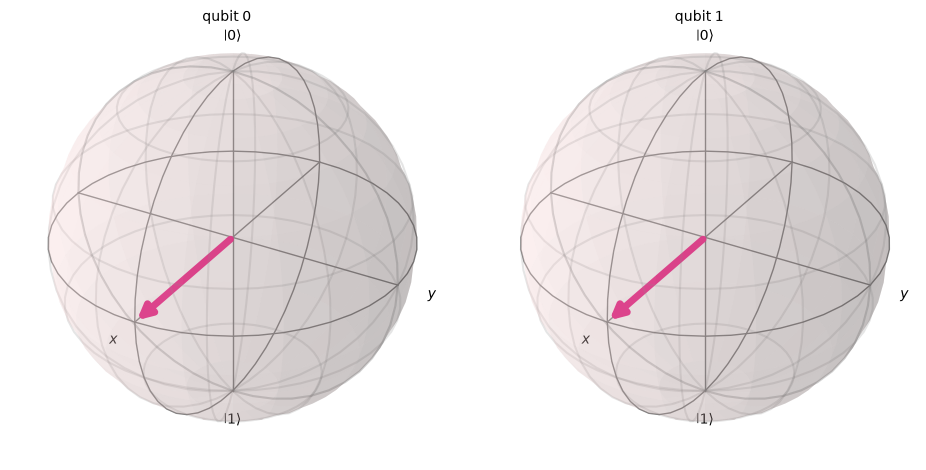

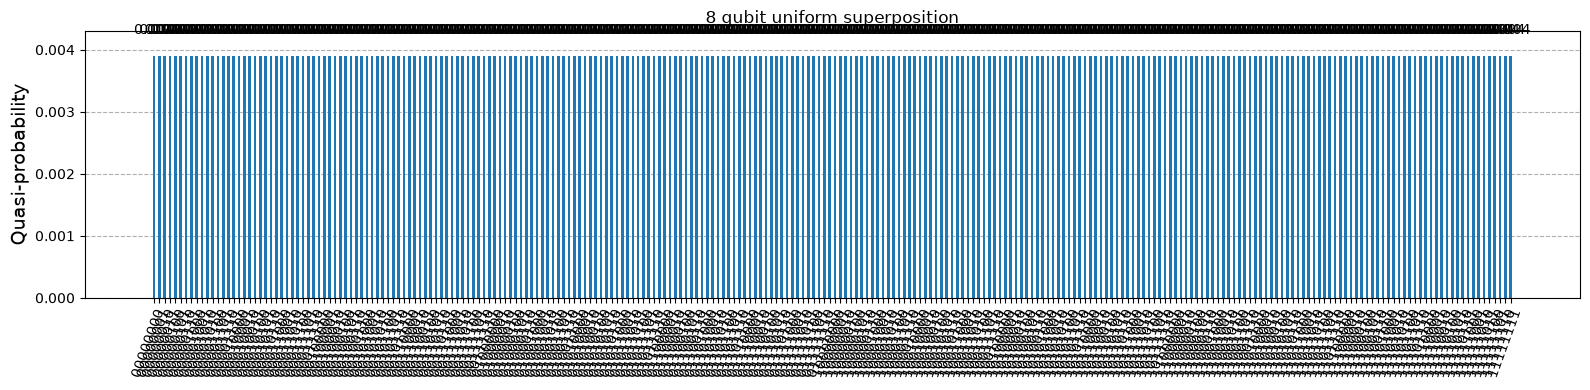

In [4]:
from qiskit.visualization import plot_histogram

# 2 qubits, 4 basis states
qc2 = QuantumCircuit(2)
qc2.h(0)
qc2.h(1)

print('2 qubit circuit with 2 haramards')
display(qc2.draw('mpl'))

sv2 = Statevector(qc2)
print('amplitudes over all 4 basis states')
for i, amp in enumerate(sv2):
    bits = format(i, '02b')
    prob = abs(amp)**2
    print(f'  |{bits}> amplitude={amp:.4f}  probability={prob:.2%}')

print('Bloch spheres')
display(plot_bloch_multivector(sv2))

# full search register
n_qubits = 8
qc8 = QuantumCircuit(n_qubits)
for i in range(n_qubits):
    qc8.h(i)

sv8 = Statevector(qc8)
probs = {format(i, '08b'): abs(amp)**2 for i, amp in enumerate(sv8)}

display(plot_histogram(probs, figsize=(16, 4), title='8 qubit uniform superposition'))